# Learning the dynamics of PDEs with LDNet (Test Case 1b)

This notebook contains a tutorial with an example of usage of an LDNet to learn the dynamics underlying the following Diffusion-Reaction equation (Test case 1b, Section 3.1.3 of the Supplementary Information):

$$
\begin{cases}
\frac{\partial z(x,t)}{\partial t} - \mu_1 \frac{\partial^2 z(x,t)}{\partial x^2} + \mu_3 z(x,t) = A(t) \cos(\pi x - P(t)), & x \in (-1,1), t\in (0,T], \\
z(-1,t) = z(1,t) & t\in (0,T], \\
z(x,0)= 0 & x \in (-1,1).
\end{cases}
$$

with parameters $\mu_1 = 0.05$ and $\mu_3 = 0.02$. The LDNet is trained in order to predict the space-time dynamics of $z(x,t)$ for a generic input $\mathbf{u}(t) = (A(t), P(t))$.

## Extension: linear reconstruction on a fixed basis

In this version of the notebook the trainable nonlinear reconstruction network $\mathcal{NN}_{\mathrm{rec}}$ is replaced by a **linear reconstruction on a fixed, a-priori basis**:

$$\tilde y(x,t) = \sum_{j=1}^{N} \varphi_j(x)\, s_j(t),$$

so that `num_latent_states = N` and the latent states are the coefficients of the basis expansion. The basis functions are **not trainable**; the dynamics network `NNdyn`, the Forward-Euler time integration and the initial condition $s(0)=0$ are unchanged.

Three bases are compared, one self-contained section each:

1. **Fourier**: $\{1, \cos(k\pi x), \sin(k\pi x)\}_{k\ge 1}$, consistent with the periodic boundary conditions.
2. **Gaussian RBF**: equally spaced centres on $(-1,1)$ with width $\varepsilon = c\,h$ ($h$ = centre spacing); **periodic (minimum-image) RBFs** are used, and $c$ is tuned on the training set only.
3. **PCA**: modes from the SVD of the training snapshot matrix **without centring**, so that $\tilde y(x,0)=0$ is preserved; the modes are evaluated at the grid points only (no interpolation).

For every basis, $N$ is chosen with a reproducible rule on a subset of the **training** set (never the test set): the smallest $N$ such that the relative $L^2$ projection error of the training fields drops below 1%, with a knee (elbow) fallback.

The original LDNet with the trainable $\mathcal{NN}_{\mathrm{rec}}$ is kept as the **baseline**, with the same data, normalisation, seed and optimizer schedule (Adam, then BFGS).

Run the **Setup** cells once, then each basis section can be run top to bottom on its own: every section re-creates its own model from the same seed.

## Setup

In [1]:
# import modules
import time
import contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats
import tensorflow as tf

# We configure TensorFlow to work in double precision
tf.keras.backend.set_floatx('float64')

# Double precision must run on the CPU here: the Apple Metal GPU plugin only registers
# single-precision kernels (e.g. ResourceApplyAdam with T=DT_DOUBLE is missing).
# We first try to hide the GPU; if the kernel already initialized it (e.g. this cell is
# re-run in an old session), we fall back to creating all model variables on /CPU:0.
try:
    tf.config.set_visible_devices([], 'GPU')
except RuntimeError:
    pass  # devices already initialized: fall back to the CPU device scope below
if tf.config.get_visible_devices('GPU'):
    print('GPU already initialized -> model variables will be created on /CPU:0.')
    cpu_device = lambda: tf.device('/CPU:0')
else:
    print('Running on CPU (float64).')
    cpu_device = contextlib.nullcontext

import utils
import optimization

# utils.py and optimization.py have been copied into this folder from src/ without modifications.
print('utils        ->', utils.__file__)
print('optimization ->', optimization.__file__)

/Users/giuliodonninelli/Dev/LDNets/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Running on CPU (float64).
utils        -> /Users/giuliodonninelli/Dev/LDNets/tests_1b/utils.py
optimization -> /Users/giuliodonninelli/Dev/LDNets/tests_1b/optimization.py


### Problem setting

We define the name of the variables of the problem at hand.

In [2]:
problem = {
    'space': {
        'dimension' : 1
    },
    'input_parameters': [],
    'input_signals': [
        { 'name': 'amplitude' },
        { 'name': 'phase' }
    ],
    'output_fields': [
        { 'name': 'z' }
    ]
}

We define, for each variable, a lower and an upper bound to be used to normalize the data.

In [3]:
normalization = {
    'space': { 'min' : [-1], 'max' : [+1]},
    'time': { 'time_constant' : 2.3 },
    'input_signals': {
        'amplitude': { 'min':   0, 'max': 0.8},
        'phase'    : { 'min':  -4, 'max': 4 },
    },
    'output_fields': {
        'z': { 'min': -1, 'max': +1 }
    }
}

We define the time step size and the number of latent variables used by the LDNet.

The baseline uses `num_latent_states = 2`; each fixed-basis section sets its own chosen $N$.

In [4]:
dt = 5e-2
num_latent_states = 2

### Datasets

We load training, validation and testing data. Here, training, validation and test sets comprise $n_{\mathrm{samples}} = 100$ samples each.
We resample data points on a regular grid with $n_{\mathrm{times}} = 101$ time instants and $n_{\mathrm{points}} = 100$ space points.
By following the notation of the paper, we denote by $d = 1$ the spatial dimension, by $d_{\mathbf{u}} = 2$ the number of input parameters and by $d_{\mathbf{y}} = 1$ the number of output fields.

Each dataset is stored as a Python dictionary, with the following fields (shape is indicated in square brackets):
- `times` $[n_{\mathrm{times}}]$: time instants;
- `points` $[n_{\mathrm{points}}, d]$: space points;
- `points_full` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, n_{\mathrm{points}}, d]$: space points repeated for each sample and time instant;
- `inp_signals` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, d_{\mathbf{u}}]$: input signals for each sample and time instant;
- `out_fields` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, n_{\mathrm{points}}, d_{\mathbf{y}}]$: output fields for each sample, time instant and space point.

In [5]:
data_set_path = '../data/ADR/data_1b.npy'
samples_train = np.arange(  0, 100)
samples_valid = np.arange(100, 200)
samples_tests = np.arange(200, 300)

dataset = np.load(data_set_path, allow_pickle = True)[()]
dataset_train = utils.ADR_create_dataset(dataset, samples_train)
dataset_valid = utils.ADR_create_dataset(dataset, samples_valid) 
dataset_tests = utils.ADR_create_dataset(dataset, samples_tests) 

# We re-sample the time transients with timestep dt and we rescale each variable between -1 and 1.
utils.process_dataset(dataset_train, problem, normalization, dt = dt)
utils.process_dataset(dataset_valid, problem, normalization, dt = dt)
utils.process_dataset(dataset_tests, problem, normalization, dt = dt)

## Evaluation helpers

Metrics are computed exactly as in the original notebook: normalized RMSE and Pearson dissimilarity on the denormalized fields. `summary_rows` collects the results printed in the final comparison table.

In [6]:
summary_rows = []

def error_metrics(app, ref):
    nrmse = np.sqrt(np.mean(np.square(app - ref))) / (np.max(ref) - np.min(ref))
    pearson_dissimilarity = 1.0 - scipy.stats.pearsonr(np.reshape(app, (-1,)), np.reshape(ref, (-1,)))[0]
    return nrmse, pearson_dissimilarity

def evaluate_model(LDNet):
    out_train = utils.denormalize_output(LDNet(dataset_train), problem, normalization).numpy()
    ref_train = utils.denormalize_output(dataset_train['out_fields'], problem, normalization).numpy()
    out_test = utils.denormalize_output(LDNet(dataset_tests), problem, normalization).numpy()
    ref_test = utils.denormalize_output(dataset_tests['out_fields'], problem, normalization).numpy()
    return out_train, ref_train, error_metrics(out_train, ref_train), out_test, ref_test, error_metrics(out_test, ref_test)

def add_summary_row(name, N, train_metrics, test_metrics, training_time, note = ''):
    summary_rows.append({
        'basis': name,
        'N': N,
        'train NRMSE': train_metrics[0],
        'test NRMSE': test_metrics[0],
        'train 1-rho': train_metrics[1],
        'test 1-rho': test_metrics[1],
        'training time (s)': training_time,
        'note': note,
    })

## Baseline: original LDNet with the nonlinear reconstruction network

This section is the original notebook: $\mathcal{NN}_{\mathrm{rec}}$ is a trainable fully-connected network, its weights are included in the Tikhonov regularisation and in the trainable variables passed to the optimizer.

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 10)                50        
                                                                 
 dense_1 (Dense)             (None, 10)                110       
                                                                 
 dense_2 (Dense)             (None, 2)                 22        
                                                                 
Total params: 182
Trainable params: 182
Non-trainable params: 0
_________________________________________________________________


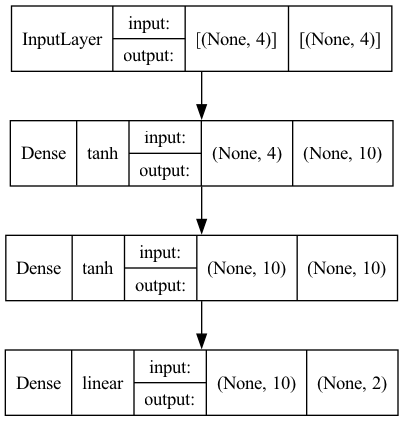

In [7]:
# For reproducibility (delete if you want to test other random initializations)
np.random.seed(0)
tf.random.set_seed(0)

# dynamics network (on the CPU device selected in the setup cell)
with cpu_device():
    input_shape = (num_latent_states + len(problem['input_parameters']) + len(problem['input_signals']),)
    NNdyn = tf.keras.Sequential([
                tf.keras.layers.Dense(10, activation = tf.nn.tanh, input_shape = input_shape),
                tf.keras.layers.Dense(10, activation = tf.nn.tanh),
                tf.keras.layers.Dense(num_latent_states)
            ])

# summary
NNdyn.summary()

# visualization
tf.keras.utils.plot_model(NNdyn, show_shapes=True, show_layer_names=False, show_layer_activations=True)

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, None, None, 7)     28        
                                                                 
 dense_4 (Dense)             (None, None, None, 7)     56        
                                                                 
 dense_5 (Dense)             (None, None, None, 1)     8         
                                                                 
Total params: 92
Trainable params: 92
Non-trainable params: 0
_________________________________________________________________


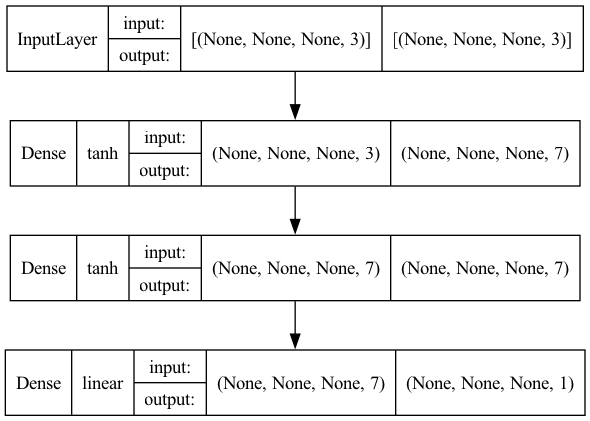

In [8]:
# reconstruction network (on the CPU device selected in the setup cell)
with cpu_device():
    input_shape = (None, None, num_latent_states + problem['space']['dimension'])
    NNrec = tf.keras.Sequential([
                tf.keras.layers.Dense(7, activation = tf.nn.tanh, input_shape = input_shape),
                tf.keras.layers.Dense(7, activation = tf.nn.tanh),
                tf.keras.layers.Dense(len(problem['output_fields']))
            ])

# summary
NNrec.summary()

# visualization
tf.keras.utils.plot_model(NNrec, show_shapes=True, show_layer_names=False, show_layer_activations=True)

The LDNet action is defined through the following two functions:
- `evolve_dynamics` computes the evolution of the latent states;
- `reconstruct_output` reconstructs the output field from the latent states evolution.

In [9]:
def evolve_dynamics(dataset):
    # intial condition
    state = tf.zeros((dataset['num_samples'], num_latent_states), dtype=tf.float64)
    state_history = tf.TensorArray(tf.float64, size = dataset['num_times'])
    state_history = state_history.write(0, state)
    dt_ref = normalization['time']['time_constant']
    
    # time integration
    for i in tf.range(dataset['num_times'] - 1):
        state = state + dt/dt_ref * NNdyn(tf.concat([state, dataset['inp_signals'][:,i,:]], axis = -1))
        state_history = state_history.write(i + 1, state)

    return tf.transpose(state_history.stack(), perm=(1,0,2))

def reconstruct_output(dataset, states):    
    states_expanded = tf.broadcast_to(tf.expand_dims(states, axis = 2), 
        [dataset['num_samples'], dataset['num_times'], dataset['num_points'], num_latent_states])
    return NNrec(tf.concat([states_expanded, dataset['points_full']], axis = 3))

def LDNet(dataset):
    states = evolve_dynamics(dataset)
    return reconstruct_output(dataset, states)

### Loss function

We define the loss function as the MSE (mean square error) over the whole dataset plus a Tikhonov regularization on the NNs' weights.

In [10]:
def MSE(dataset):
    out_fields = LDNet(dataset)
    error = out_fields - dataset['out_fields']
    return tf.reduce_mean(tf.square(error))

def weights_reg(NN):
    return sum([tf.reduce_mean(tf.square(lay.kernel)) for lay in NN.layers])/len(NN.layers)

alpha_reg = 1e-5
def loss(): return MSE(dataset_train) + alpha_reg * (weights_reg(NNdyn) + weights_reg(NNrec))
def MSE_valid(): return MSE(dataset_valid)

### LDNet training

We train the LDNet with $50$ iterations based on the Adam optimizer, followed by $150$ iterations based on the BFGS optimizer.
Notice that the trainable variables of the LDNet are given as the union of the trainable variables of $\mathcal{NN}_{\mathrm{dyn}}$ and $\mathcal{NN}_{\mathrm{rec}}$.

In [11]:
trainable_variables = NNdyn.variables + NNrec.variables

t0 = time.time()
opt = optimization.OptimizationProblem(trainable_variables, loss, MSE_valid)

num_epochs_Adam = 50
num_epochs_BFGS = 150

print('training (Adam)...')
opt.optimize_keras(num_epochs_Adam, tf.keras.optimizers.Adam(learning_rate=1e-2))
print('training (BFGS)...')
opt.optimize_BFGS(num_epochs_BFGS)
baseline_training_time = time.time() - t0

Tracing functions with autograph...


2026-09-30 21:41:27.858796: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


Tracing completed.
epoch    0   -   training loss: 2.880e-01   -   validation loss 2.790e-01
training (Adam)...
epoch   10   -   training loss: 1.230e-01   -   validation loss 1.190e-01
epoch   20   -   training loss: 1.117e-01   -   validation loss 1.091e-01
epoch   30   -   training loss: 1.002e-01   -   validation loss 9.747e-02
epoch   40   -   training loss: 8.622e-02   -   validation loss 8.502e-02
epoch   50   -   training loss: 6.580e-02   -   validation loss 6.780e-02
training (BFGS)...
epoch   60   -   training loss: 3.045e-02   -   validation loss 3.414e-02
epoch   70   -   training loss: 2.163e-02   -   validation loss 2.611e-02
epoch   80   -   training loss: 1.938e-02   -   validation loss 2.318e-02
epoch   90   -   training loss: 1.723e-02   -   validation loss 2.065e-02
epoch  100   -   training loss: 1.536e-02   -   validation loss 1.853e-02
epoch  110   -   training loss: 1.307e-02   -   validation loss 1.594e-02
epoch  120   -   training loss: 1.047e-02   -   validat

We plot the progress of training and validation MSE during the advancement of epochs.

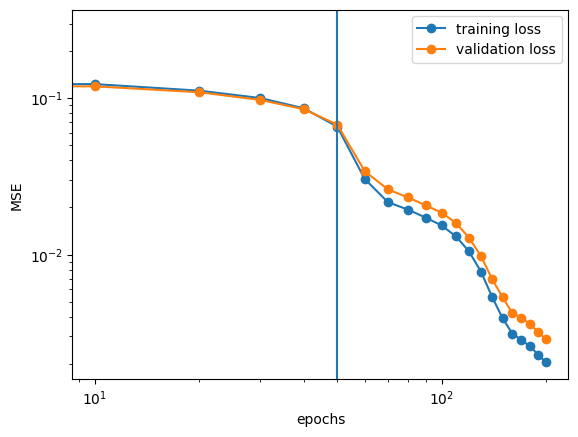

In [12]:
plt.loglog(opt.iterations_history, opt.loss_train_history, 'o-', label = 'training loss')
plt.loglog(opt.iterations_history, opt.loss_valid_history, 'o-', label = 'validation loss')
plt.axvline(num_epochs_Adam)
plt.xlabel('epochs'), plt.ylabel('MSE')
plt.legend()
plt.show()

### Testing

We predict the output field on the testing samples, and we compute error metrics: the normalized root mean square error and the Pearson dissimilarity.

In [13]:
out_train, ref_train, train_metrics, out_test, ref_test, test_metrics = evaluate_model(LDNet)

print('Normalized RMSE (train): %1.3e' % train_metrics[0])
print('Normalized RMSE (test):  %1.3e' % test_metrics[0])
print('Pearson dissimilarity (train): %1.3e' % train_metrics[1])
print('Pearson dissimilarity (test):  %1.3e' % test_metrics[1])

add_summary_row('NNrec (MLP, nonlinear)', num_latent_states, train_metrics, test_metrics,
                baseline_training_time, note = 'baseline: original notebook')

Normalized RMSE (train): 1.914e-02
Normalized RMSE (test):  2.440e-02
Pearson dissimilarity (train): 7.859e-03
Pearson dissimilarity (test):  1.052e-02


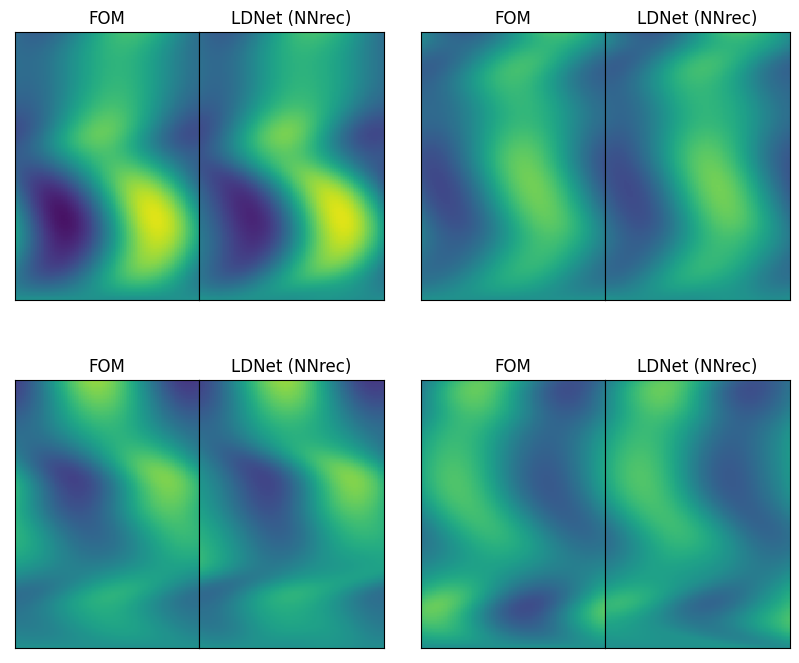

In [14]:
utils.plot_output_1D(dataset_tests, ref_test, out_test, 2, 2, title_ROM = 'LDNet (NNrec)')
plt.show()

## Fixed-basis helpers

Basis selection uses **only a subset of the training set** (the first 50 training samples); the test set is never touched until the final evaluation.

- The **relative $L^2$ projection error** of the training fields is the error of the best least-squares projection of the snapshots onto the span of the first $N$ basis functions, relative to the norm of the snapshots.
- **$N$ selection rule** (`pick_N`, reproducible): the smallest $N$ with relative projection error below $1\%$; if the threshold is never reached, the knee of the log-error curve (maximum distance to the chord joining its endpoints). The rule that was applied is printed.

For the fixed-basis models the latent states are the basis coefficients and the reconstruction is a matrix product between the states and the basis evaluated at the points; `NNrec` does not exist, so only the weights of `NNdyn` enter the regularisation and the trainable variables. The optimizer schedule is the same as the baseline (50 Adam + 150 BFGS).

In [ ]:
# ---- Basis-selection helpers (TRAINING set only) ----
N_SELECTION_SAMPLES = 50   # subset of the training set used to tune the RBF width and to choose N
points = dataset_train['points'][:, 0]                                    # [num_points], normalized grid in [-1, 1]
snapshots = dataset_train['out_fields'].numpy()[:N_SELECTION_SAMPLES]     # [n_sel, n_times, num_points, 1]
snapshots = snapshots.reshape(-1, dataset_train['num_points'])            # [n_sel*n_times, num_points]

def rel_proj_error(Phi, X):
    '''Relative L2 error of the best least-squares projection of the snapshots X onto span(Phi).'''
    coeffs, *_ = np.linalg.lstsq(Phi, X.T, rcond=None)
    return np.linalg.norm(X - (coeffs.T @ Phi.T)) / np.linalg.norm(X)

def pick_N(Ns, errors, tol = 1e-2):
    '''Reproducible selection: smallest N with relative projection error < tol;
    fallback: knee of the log-error curve (max distance to the chord).'''
    for N, e in zip(Ns, errors):
        if e < tol:
            return N, 'smallest N with relative projection error < 1%'
    x = np.asarray(Ns, dtype=float); y = np.log10(np.asarray(errors))
    x = (x - x[0]) / (x[-1] - x[0]); y = (y - y[0]) / (y[-1] - y[0])
    d = np.abs((y[-1] - y[0]) * x - (x[-1] - x[0]) * y + x[-1] * y[0] - y[-1] * x[0]) / np.hypot(y[-1] - y[0], x[-1] - x[0])
    return Ns[int(np.argmax(d))], 'knee of the log-error curve (max distance to the chord)'

def plot_projection_errors(Ns, curves, labels, title):
    plt.figure()
    for errors, label in zip(curves, labels):
        plt.semilogy(Ns, errors, 'o-', label=label)
    plt.axhline(1e-2, color='k', linestyle='--', linewidth=1, label='1% threshold')
    plt.xlabel('N (number of basis functions / latent states)')
    plt.ylabel('relative L2 projection error (training subset)')
    plt.title(title)
    plt.grid(True, which='both', alpha=0.3)
    plt.legend()

# ---- Linear LDNet: fixed (non-trainable) basis, latent states = basis coefficients ----
NUM_EPOCHS_ADAM = 50
NUM_EPOCHS_BFGS = 150
alpha_reg = 1e-5

def make_linear_ldnet(Phi_np):
    '''LDNet with linear reconstruction: sum_j phi_j(x) s_j(t), Phi_np = basis at the grid points [num_points, N].'''
    N = Phi_np.shape[1]
    np.random.seed(0)
    tf.random.set_seed(0)
    with cpu_device():
        NNdyn = tf.keras.Sequential([
            tf.keras.layers.Dense(10, activation=tf.nn.tanh, input_shape=(N + len(problem['input_signals']),)),
            tf.keras.layers.Dense(10, activation=tf.nn.tanh),
            tf.keras.layers.Dense(N),
        ])
    Phi = tf.constant(Phi_np, dtype=tf.float64)   # fixed, not trainable

    def evolve_dynamics(dataset):
        state = tf.zeros((dataset['num_samples'], N), dtype=tf.float64)
        state_history = tf.TensorArray(tf.float64, size=dataset['num_times'])
        state_history = state_history.write(0, state)
        dt_ref = normalization['time']['time_constant']
        for i in tf.range(dataset['num_times'] - 1):
            state = state + dt / dt_ref * NNdyn(tf.concat([state, dataset['inp_signals'][:, i, :]], axis=-1))
            state_history = state_history.write(i + 1, state)
        return tf.transpose(state_history.stack(), perm=(1, 0, 2))

    def reconstruct_output(dataset, states):
        # matrix product between the states [samples, times, N] and the basis at the points [points, N]
        return tf.matmul(states, Phi, transpose_b=True)[..., tf.newaxis]

    def LDNet(dataset):
        return reconstruct_output(dataset, evolve_dynamics(dataset))

    def MSE(dataset):
        return tf.reduce_mean(tf.square(LDNet(dataset) - dataset['out_fields']))

    def weights_reg(nn):
        return sum([tf.reduce_mean(tf.square(lay.kernel)) for lay in nn.layers]) / len(nn.layers)

    def loss():
        return MSE(dataset_train) + alpha_reg * weights_reg(NNdyn)   # NNdyn only: no NNrec

    def MSE_valid():
        return MSE(dataset_valid)

    return NNdyn, LDNet, loss, MSE_valid

def train_linear_basis(name, Phi_np, note = ''):
    NNdyn, LDNet, loss, MSE_valid = make_linear_ldnet(Phi_np)
    t0 = time.time()
    opt = optimization.OptimizationProblem(NNdyn.variables, loss, MSE_valid)   # no NNrec variables
    print('training (Adam)...')
    opt.optimize_keras(NUM_EPOCHS_ADAM, tf.keras.optimizers.Adam(learning_rate=1e-2))
    print('training (BFGS)...')
    opt.optimize_BFGS(NUM_EPOCHS_BFGS)
    training_time = time.time() - t0
    out_train, ref_train, train_metrics, out_test, ref_test, test_metrics = evaluate_model(LDNet)
    add_summary_row(name, Phi_np.shape[1], train_metrics, test_metrics, training_time, note)
    print('basis: %s, N = %d' % (name, Phi_np.shape[1]))
    print('Normalized RMSE (train): %1.3e   Pearson dissimilarity (train): %1.3e' % train_metrics)
    print('Normalized RMSE (test):  %1.3e   Pearson dissimilarity (test):  %1.3e' % test_metrics)
    return LDNet, opt, out_test, ref_test

## 1. Fourier basis

The basis is $\{1, \cos(\pi x), \sin(\pi x), \cos(2\pi x), \sin(2\pi x), \dots\}$, truncated to the first $N$ functions in this order. Every function is 2-periodic in $x$, hence consistent with the periodic boundary conditions of Test Case 1b.

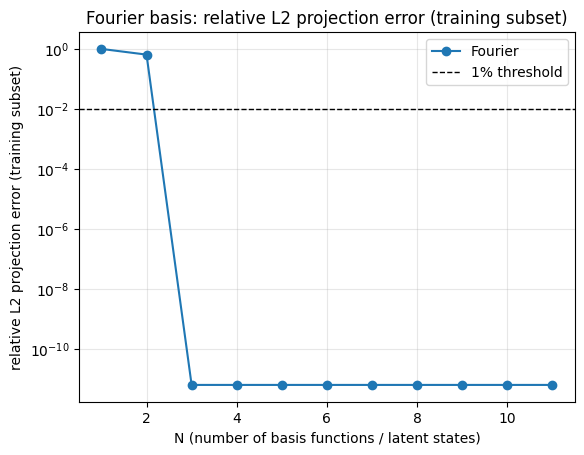

Chosen N (Fourier): 3  ->  smallest N with relative projection error < 1%
relative L2 projection error at N = 3: 6.398e-12


In [16]:
def fourier_basis(x, N):
    '''Ordered Fourier basis {1, cos(pi x), sin(pi x), cos(2 pi x), sin(2 pi x), ...}.'''
    cols = [np.ones_like(x)]
    k = 1
    while len(cols) < N:
        cols.append(np.cos(k * np.pi * x))
        if len(cols) < N:
            cols.append(np.sin(k * np.pi * x))
        k += 1
    return np.stack(cols, axis=1)

Ns_fourier = np.arange(1, 12)
err_fourier = [rel_proj_error(fourier_basis(points, N), snapshots) for N in Ns_fourier]

plot_projection_errors(Ns_fourier, [err_fourier], ['Fourier'],
                       'Fourier basis: relative L2 projection error (training subset)')
plt.show()

N_fourier, rule_fourier = pick_N(Ns_fourier, err_fourier)
print('Chosen N (Fourier): %d  ->  %s' % (N_fourier, rule_fourier))
print('relative L2 projection error at N = %d: %1.3e' % (N_fourier, dict(zip(Ns_fourier, err_fourier))[N_fourier]))

In [17]:
LDNet_fourier, opt_fourier, out_test_fourier, ref_test_fourier = train_linear_basis(
    'Fourier', fourier_basis(points, N_fourier),
    note = 'fixed non-trainable basis {1, cos(k pi x), sin(k pi x)}')

Tracing functions with autograph...
Tracing completed.
epoch    0   -   training loss: 3.855e-01   -   validation loss 4.179e-01
training (Adam)...
epoch   10   -   training loss: 1.982e-01   -   validation loss 1.920e-01
epoch   20   -   training loss: 1.126e-01   -   validation loss 1.097e-01
epoch   30   -   training loss: 9.174e-02   -   validation loss 8.937e-02
epoch   40   -   training loss: 7.516e-02   -   validation loss 7.343e-02
epoch   50   -   training loss: 6.559e-02   -   validation loss 6.488e-02
training (BFGS)...
epoch   60   -   training loss: 4.318e-02   -   validation loss 5.501e-02
epoch   70   -   training loss: 4.004e-02   -   validation loss 5.055e-02
epoch   80   -   training loss: 2.504e-02   -   validation loss 3.295e-02
epoch   90   -   training loss: 9.783e-03   -   validation loss 1.405e-02
epoch  100   -   training loss: 6.239e-03   -   validation loss 9.219e-03
epoch  110   -   training loss: 3.779e-03   -   validation loss 5.872e-03
epoch  120   -   tr

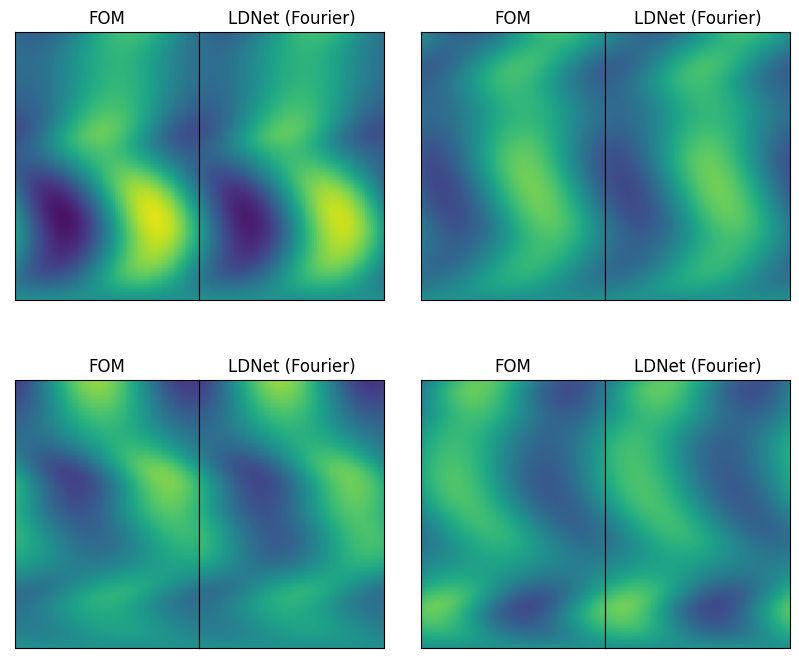

In [18]:
utils.plot_output_1D(dataset_tests, ref_test_fourier, out_test_fourier, 2, 2, title_ROM = 'LDNet (Fourier)')
plt.show()

## 2. Gaussian RBF basis

The basis functions are Gaussian RBFs centred at $N$ equally spaced points on $(-1,1)$ (spacing $h = 2/N$):

$$\varphi_j(x) = \exp\!\left(-\left(\frac{d_\mathrm{per}(x, c_j)}{\varepsilon}\right)^2\right), \qquad \varepsilon = c\,h,$$

where $d_\mathrm{per}$ is the **periodic (minimum-image) distance** on the period-2 domain: we use **periodic RBFs**, since the problem has periodic boundary conditions. The shape parameter $c$ is tuned on the training subset only: a grid of candidate values is scanned and the value with the smallest mean (log) projection error over the considered range of $N$ is kept.

Tuned RBF width: eps = c * h with c = 2


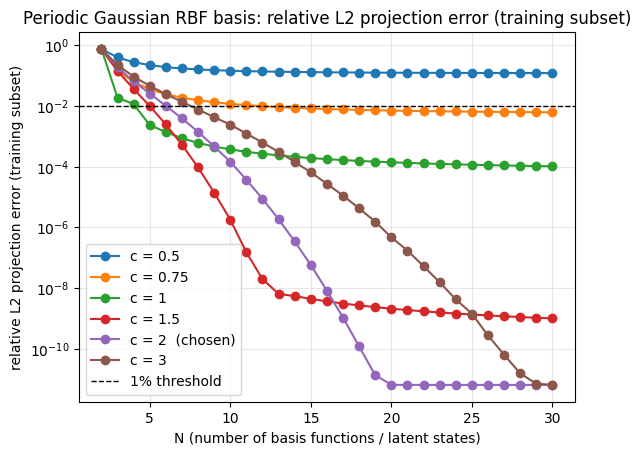

Chosen N (RBF): 7  ->  smallest N with relative projection error < 1%
relative L2 projection error at N = 7: 3.935e-03


In [19]:
def periodic_rbf_basis(x, N, c_shape):
    '''Periodic (minimum-image) Gaussian RBFs: N equally spaced centres on (-1, 1),
    spacing h = 2/N, width eps = c_shape * h.'''
    spacing = 2.0 / N
    centers = -1.0 + (np.arange(N) + 0.5) * spacing
    d = np.abs(x[:, None] - centers[None, :])
    d = np.minimum(d, 2.0 - d)   # periodic distance on the period-2 domain
    return np.exp(-(d / (c_shape * spacing)) ** 2)

Ns_rbf = np.arange(2, 31)
c_candidates = [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
errs_by_c = {c: [rel_proj_error(periodic_rbf_basis(points, N, c), snapshots) for N in Ns_rbf] for c in c_candidates}
c_rbf = min(c_candidates, key = lambda c: np.mean(np.log10(errs_by_c[c])))
print('Tuned RBF width: eps = c * h with c = %g' % c_rbf)

plot_projection_errors(Ns_rbf, [errs_by_c[c] for c in c_candidates],
                       ['c = %g%s' % (c, '  (chosen)' if c == c_rbf else '') for c in c_candidates],
                       'Periodic Gaussian RBF basis: relative L2 projection error (training subset)')
plt.show()

N_rbf, rule_rbf = pick_N(Ns_rbf, errs_by_c[c_rbf])
print('Chosen N (RBF): %d  ->  %s' % (N_rbf, rule_rbf))
print('relative L2 projection error at N = %d: %1.3e' % (N_rbf, dict(zip(Ns_rbf, errs_by_c[c_rbf]))[N_rbf]))

In [20]:
LDNet_rbf, opt_rbf, out_test_rbf, ref_test_rbf = train_linear_basis(
    'RBF (periodic)', periodic_rbf_basis(points, N_rbf, c_rbf),
    note = 'periodic Gaussian RBFs, eps = %g * h' % c_rbf)

Tracing functions with autograph...
Tracing completed.
epoch    0   -   training loss: 2.097e-01   -   validation loss 2.172e-01
training (Adam)...
epoch   10   -   training loss: 5.409e-02   -   validation loss 6.054e-02
epoch   20   -   training loss: 4.657e-02   -   validation loss 5.662e-02
epoch   30   -   training loss: 4.428e-02   -   validation loss 5.615e-02
epoch   40   -   training loss: 4.354e-02   -   validation loss 5.546e-02
epoch   50   -   training loss: 4.315e-02   -   validation loss 5.550e-02
training (BFGS)...
epoch   60   -   training loss: 4.238e-02   -   validation loss 5.415e-02
epoch   70   -   training loss: 3.706e-02   -   validation loss 4.489e-02
epoch   80   -   training loss: 2.015e-02   -   validation loss 2.688e-02
epoch   90   -   training loss: 1.332e-02   -   validation loss 1.994e-02
epoch  100   -   training loss: 9.410e-03   -   validation loss 1.363e-02
epoch  110   -   training loss: 6.391e-03   -   validation loss 9.716e-03
epoch  120   -   tr

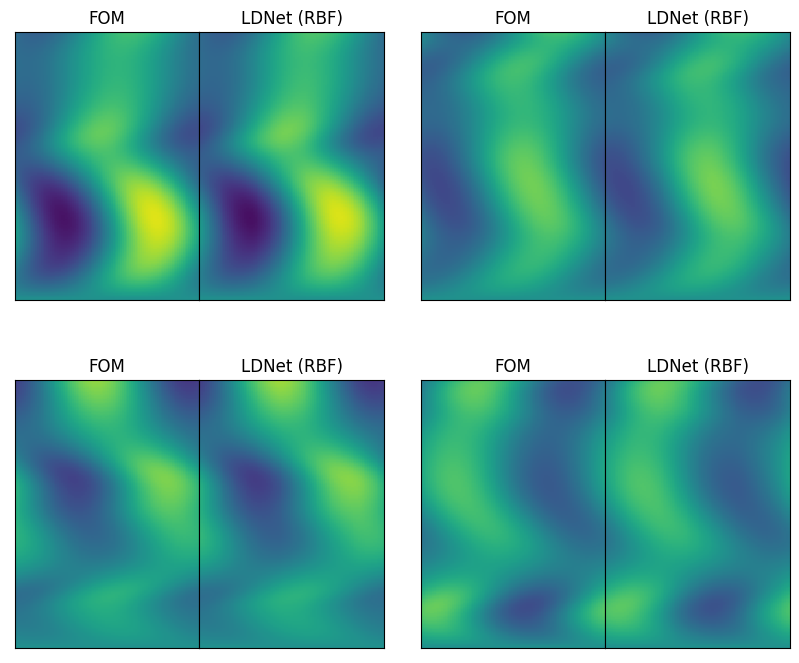

In [21]:
utils.plot_output_1D(dataset_tests, ref_test_rbf, out_test_rbf, 2, 2, title_ROM = 'LDNet (RBF)')
plt.show()

## 3. PCA basis

We compute the SVD **without centring** of the training snapshot matrix $X$ (snapshots on the rows, grid points on the columns), $X = U\Sigma V^\top$, and use the first $N$ right singular vectors as basis functions, $\varphi_j(x_i) = V_{ij}$.

- **No centring** is used, so the linear reconstruction vanishes when $s = 0$: since the model keeps $s(0)=0$, the initial condition $\tilde y(x,0)=0$ is preserved exactly. (With centring, the reconstruction would be $\bar y(x) + \sum_j \varphi_j(x) s_j(t)$ and the initial condition would require $s(0)$ equal to the projection of the initial field onto the centred modes, not zero.)
- The modes are available **only at the grid points** used to build them; no interpolation is performed, so the reconstruction is evaluated on mesh points only. All datasets share the same 100-point grid. This is a limitation compared with the meshless $\mathcal{NN}_{\mathrm{rec}}$.

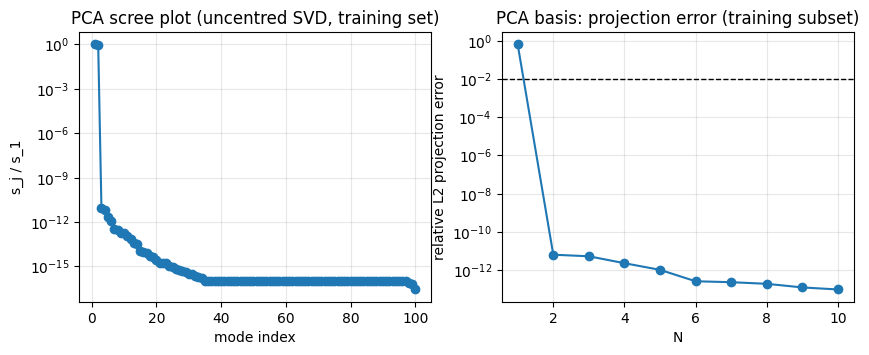

Chosen N (PCA): 2  ->  smallest N with relative projection error < 1%
relative L2 projection error at N = 2: 6.398e-12


In [22]:
# Uncentred SVD of the TRAINING snapshot matrix: X = U S V^T
X_train_all = dataset_train['out_fields'].numpy().reshape(-1, dataset_train['num_points'])
_, singular_values, Vt = np.linalg.svd(X_train_all, full_matrices=False)
pca_modes = Vt.T   # [num_points, num_modes], evaluated at the grid points (no interpolation)

Ns_pca = np.arange(1, 11)
err_pca = [rel_proj_error(pca_modes[:, :N], snapshots) for N in Ns_pca]

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].semilogy(np.arange(1, len(singular_values) + 1), singular_values / singular_values[0], 'o-')
axs[0].set_xlabel('mode index'); axs[0].set_ylabel('s_j / s_1')
axs[0].set_title('PCA scree plot (uncentred SVD, training set)')
axs[0].grid(True, which='both', alpha=0.3)
axs[1].semilogy(Ns_pca, err_pca, 'o-')
axs[1].axhline(1e-2, color='k', linestyle='--', linewidth=1)
axs[1].set_xlabel('N'); axs[1].set_ylabel('relative L2 projection error')
axs[1].set_title('PCA basis: projection error (training subset)')
axs[1].grid(True, which='both', alpha=0.3)
plt.show()

N_pca, rule_pca = pick_N(Ns_pca, err_pca)
print('Chosen N (PCA): %d  ->  %s' % (N_pca, rule_pca))
print('relative L2 projection error at N = %d: %1.3e' % (N_pca, dict(zip(Ns_pca, err_pca))[N_pca]))

In [23]:
LDNet_pca, opt_pca, out_test_pca, ref_test_pca = train_linear_basis(
    'PCA (uncentred)', pca_modes[:, :N_pca],
    note = 'uncentred SVD of training snapshots, modes on grid points only')

Tracing functions with autograph...
Tracing completed.
epoch    0   -   training loss: 1.317e-01   -   validation loss 1.240e-01
training (Adam)...
epoch   10   -   training loss: 7.348e-02   -   validation loss 7.650e-02
epoch   20   -   training loss: 5.957e-02   -   validation loss 6.316e-02
epoch   30   -   training loss: 5.004e-02   -   validation loss 5.544e-02
epoch   40   -   training loss: 4.306e-02   -   validation loss 5.192e-02
epoch   50   -   training loss: 3.880e-02   -   validation loss 4.802e-02
training (BFGS)...
epoch   60   -   training loss: 3.185e-02   -   validation loss 4.159e-02
epoch   70   -   training loss: 2.597e-02   -   validation loss 3.460e-02
epoch   80   -   training loss: 2.078e-02   -   validation loss 2.727e-02
epoch   90   -   training loss: 1.610e-02   -   validation loss 2.059e-02
epoch  100   -   training loss: 1.324e-02   -   validation loss 1.812e-02
epoch  110   -   training loss: 1.111e-02   -   validation loss 1.506e-02
epoch  120   -   tr

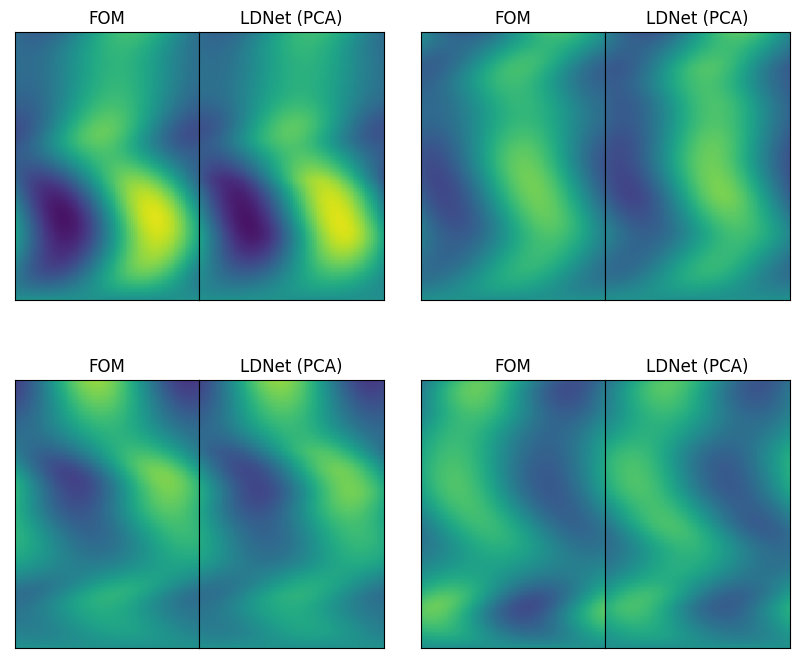

In [24]:
utils.plot_output_1D(dataset_tests, ref_test_pca, out_test_pca, 2, 2, title_ROM = 'LDNet (PCA)')
plt.show()

## Comparison

All results are computed on the same data, normalisation and split, with the same seed and the same optimizer schedule (50 Adam + 150 BFGS epochs). `N` is the number of latent states (i.e. the number of basis functions for the fixed-basis models). The baseline uses $N=2$ latent states and the trainable nonlinear $\mathcal{NN}_{\mathrm{rec}}$. Training time includes function tracing and covers the whole optimization (Adam + BFGS).

In [25]:
df = pd.DataFrame(summary_rows)[['basis', 'N', 'train NRMSE', 'test NRMSE', 'train 1-rho', 'test 1-rho', 'training time (s)', 'note']]
print(df.to_string(index=False, float_format = lambda v: '%1.3e' % v))

                 basis  N  train NRMSE  test NRMSE  train 1-rho  test 1-rho  training time (s)                                                           note
NNrec (MLP, nonlinear)  2    1.914e-02   2.440e-02    7.859e-03   1.052e-02          1.312e+01                                    baseline: original notebook
               Fourier  3    9.959e-03   1.636e-02    2.121e-03   4.655e-03          3.630e+00        fixed non-trainable basis {1, cos(k pi x), sin(k pi x)}
        RBF (periodic)  7    1.254e-02   2.179e-02    3.360e-03   8.289e-03          4.254e+00                            periodic Gaussian RBFs, eps = 2 * h
       PCA (uncentred)  2    2.371e-02   3.445e-02    1.201e-02   2.108e-02          3.509e+00 uncentred SVD of training snapshots, modes on grid points only
